<a href="https://colab.research.google.com/github/Astgenne-Moore/MAEG_Coursework/blob/main/MAEG(CNN).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import torchvision
import torch.nn as nn
from tqdm import tqdm
import multiprocessing
import torch.optim as optim
import torch.nn.functional as  F
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torchvision import transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device: ", device)

Device:  cpu


In [ ]:
## Data augmentation

train_transform = transforms.Compose([
  transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.1),
    transforms.RandomPerspective(distortion_scale=0.5, p=0.5),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
])

In [ ]:
## Dataset class

class CIFAR10_dataset(Dataset):

    def __init__(self, partition = "train", transform = None):

        print("\nLoading CIFAR10 ", partition, " Dataset...")
        self.partition = partition
        self.transform = transform
        if self.partition == "train":
            self.data = torchvision.datasets.CIFAR10('.data/',
                                                     train=True,
                                                     download=True)
        else:
            self.data = torchvision.datasets.CIFAR10('.data/',
                                                     train=False,
                                                     download=True)
        print("\tTotal Len.: ", len(self.data), "\n", 50*"-")

    def from_pil_to_tensor(self, image):
        return torchvision.transforms.ToTensor()(image)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):

        # Image
        image = self.data[idx][0]
        image_tensor = self.transform(image)

        # Label
        label = torch.tensor(self.data[idx][1])
        label = F.one_hot(label, num_classes=10).float()

        return {"img": image_tensor, "label": label}

train_dataset = CIFAR10_dataset(partition="train", transform=train_transform)
test_dataset = CIFAR10_dataset(partition="test", transform=test_transform)

batch_size = 100
num_workers = multiprocessing.cpu_count()-1
print("Num workers", num_workers)
train_dataloader = DataLoader(train_dataset, batch_size, shuffle=True, num_workers=num_workers)
test_dataloader = DataLoader(test_dataset, batch_size, shuffle=False, num_workers=num_workers)


Loading CIFAR10  train  Dataset...


100%|██████████| 170M/170M [00:04<00:00, 42.2MB/s]


	Total Len.:  50000 
 --------------------------------------------------

Loading CIFAR10  test  Dataset...
	Total Len.:  10000 
 --------------------------------------------------
Num workers 1


In [ ]:
## Define the CNN model
class AdvancedCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(AdvancedCNN, self).__init__()
        # Convolutional Layers
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32 * 2, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(in_channels=32 * 2, out_channels=64 * 2, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(in_channels=64 * 2, out_channels=64 * 2, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(in_channels=64 * 2, out_channels=128 * 2, kernel_size=3, padding=1)
        self.conv5 = nn.Conv2d(in_channels=128 * 2, out_channels=128 * 2, kernel_size=3, padding=1)
        self.conv6 = nn.Conv2d(in_channels=128 * 2, out_channels=128 * 2, kernel_size=3, padding=1)
        self.conv7 = nn.Conv2d(in_channels=128 * 2, out_channels=256 * 2, kernel_size=3, padding=1)
        self.conv8 = nn.Conv2d(in_channels=256 * 2, out_channels=256 * 2, kernel_size=3, padding=1)
        self.conv9 = nn.Conv2d(in_channels=256 * 2, out_channels=256 * 2, kernel_size=3, padding=1)
        # Batch Normalization Layers
        self.bn1 = nn.BatchNorm2d(32 * 2)
        self.bn2 = nn.BatchNorm2d(128 * 2)
        self.bn3 = nn.BatchNorm2d(256 * 2)
        # Pooling and Dropout Layers
        self.maxpool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.dropout = nn.Dropout2d(0.2)
        # Fully Connected Layers
        self.fc1 = nn.Linear(4096 * 2, 4096 * 2)
        self.fc2 = nn.Linear(4096 * 2, 2048 * 2)
        self.fc3 = nn.Linear(2048 * 2, num_classes)
        # Activation Function
        self.relu = nn.ReLU()

    def forward(self, x):
        # Convolutional Block 1
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.relu(self.conv2(x))
        x = self.relu(self.conv3(x))
        x = self.maxpool(x)
        # Convolutional Block 2
        x = self.relu(self.bn2(self.conv4(x)))
        x = self.relu(self.conv5(x))
        x = self.relu(self.conv6(x))
        x = self.maxpool(x)
        x = self.dropout(x)
        # Convolutional Block 3
        x = self.relu(self.bn3(self.conv7(x)))
        x = self.relu(self.conv8(x))
        x = self.relu(self.conv9(x))
        x = self.maxpool(x)
        x = self.dropout(x)
        # Flatten and Fully Connected Layers
        x = torch.flatten(x, start_dim=1)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.dropout(x)
        x = self.fc3(x)
        return x


# Instantiating the network and printing its architecture
num_classes = 10
net = AdvancedCNN(num_classes)
print(net)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Params: ", count_parameters(net))

AdvancedCNN(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv6): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv7): Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv8): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv9): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (bn2): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (bn3): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (maxpool)

In [ ]:
# Training hyperparameters
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.01, weight_decay=1e-6, momentum=0.9)
lr_scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.1, patience=10, min_lr=0.00001)
epochs = 100
train_losses = []
test_losses = []
train_accuracies = []
test_accuracies = []
# Load model in GPU
net.to(device)

print("\n---- Start Training ----")
best_accuracy = -1
best_epoch = 0
for epoch in range(epochs):

    # TRAIN NETWORK
    train_loss, train_correct = 0, 0
    net.train()
    num_batches = 0
    with tqdm(iter(train_dataloader), desc="Epoch " + str(epoch), unit="batch") as tepoch:
        for batch in tepoch:

            # Returned values of Dataset Class
            images = batch["img"].to(device)
            labels = batch["label"].to(device)

            # zero the parameter gradients
            optimizer.zero_grad()

            # Forward
            outputs = net(images)
            loss = criterion(outputs, labels)

            # Calculate gradients
            loss.backward()

            # Update gradients
            optimizer.step()

            # one hot -> labels (if necessary)
            if len(labels.shape) > 1:
                labels = torch.argmax(labels, dim=1)
            pred = torch.argmax(outputs, dim=1)
            train_correct += pred.eq(labels).sum().item()

            # print statistics
            train_loss += loss.item()
            num_batches += 1

    train_loss /= num_batches
    train_losses.append(train_loss)

    # TEST NETWORK
    test_loss, test_correct = 0, 0
    net.eval()
    num_test_batches = 0
    with torch.no_grad():
      with tqdm(iter(test_dataloader), desc="Test " + str(epoch), unit="batch") as tepoch:
          for batch in tepoch:

            images = batch["img"].to(device)
            labels = batch["label"].to(device)

            # Forward
            outputs = net(images)
            test_loss += criterion(outputs, labels).item()

            # one hot -> labels (if necessary)
            if len(labels.shape) > 1:
                labels = torch.argmax(labels, dim=1)
            pred = torch.argmax(outputs, dim=1)

            test_correct += pred.eq(labels).sum().item()
            num_test_batches += 1

    test_loss /= num_test_batches
    test_losses.append(test_loss)
    lr_scheduler.step(test_loss)  # Pass average test loss

    test_accuracy = 100. * test_correct / len(test_dataloader.dataset)
    train_accuracies.append(100. * train_correct / len(train_dataloader.dataset))
    test_accuracies.append(test_accuracy)

    print("[Epoch {}] Train Loss: {:.6f} - Test Loss: {:.6f} - Train Accuracy: {:.2f}% - Test Accuracy: {:.2f}%".format(
        epoch + 1, train_loss, test_loss, 100. * train_correct / len(train_dataloader.dataset), test_accuracy
    ))

    if test_accuracy > best_accuracy:
        best_accuracy = test_accuracy
        best_epoch = epoch

        # Save best weights
        torch.save(net.state_dict(), "best_model.pt")

print("\nBEST TEST ACCURACY: ", best_accuracy, " in epoch ", best_epoch)



---- Start Training ----


Test 0: 100%|██████████| 100/100 [00:03<00:00, 26.88batch/s]


[Epoch 1] Train Loss: 1.259011 - Test Loss: 1.038954 - Train Accuracy: 54.19% - Test Accuracy: 63.11%


Test 1: 100%|██████████| 100/100 [00:04<00:00, 23.39batch/s]


[Epoch 2] Train Loss: 1.019592 - Test Loss: 1.037218 - Train Accuracy: 63.71% - Test Accuracy: 65.23%


...

[Epoch 98] Train Loss: 0.069420 - Test Loss: 0.285410 - Train Accuracy: 97.58% - Test Accuracy: 93.19%



Test 98: 100%|██████████| 100/100 [00:04<00:00, 24.39batch/s]

[Epoch 99] Train Loss: 0.067646 - Test Loss: 0.283873 - Train Accuracy: 97.66% - Test Accuracy: 93.22%



Test 99: 100%|██████████| 100/100 [00:04<00:00, 24.34batch/s]

[Epoch 100] Train Loss: 0.068124 - Test Loss: 0.284452 - Train Accuracy: 97.65% - Test Accuracy: 93.09%

BEST TEST ACCURACY:  93.25  in epoch  71


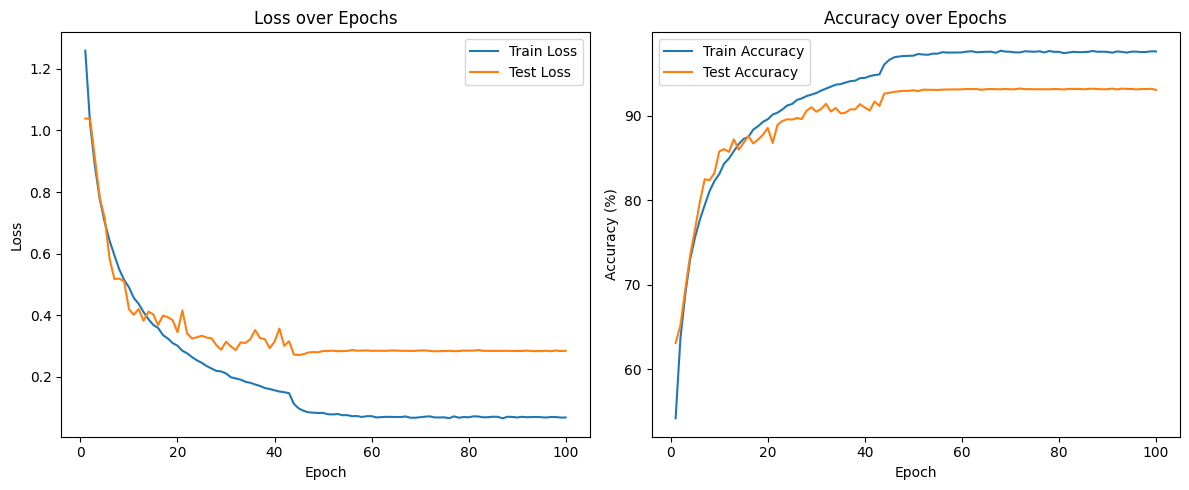

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(12, 5))

# Loss curve
plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, label='Train Loss')
plt.plot(epochs, test_losses, label='Test Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Accuracy curve
plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, label='Train Accuracy')
plt.plot(epochs, test_accuracies, label='Test Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()

plt.tight_layout()
plt.show()

/usr/local/lib/python3.11/dist-packages/torch/nn/functional.py:1538: UserWarning: dropout2d: Received a 2-D input to dropout2d, which is deprecated and will result in an error in a future release. To retain the behavior and silence this warning, please use dropout instead. Note that dropout2d exists to provide channel-wise dropout on inputs with 2 spatial dimensions, a channel dimension, and an optional batch dimension (i.e. 3D or 4D inputs).
  warnings.warn(warn_msg)


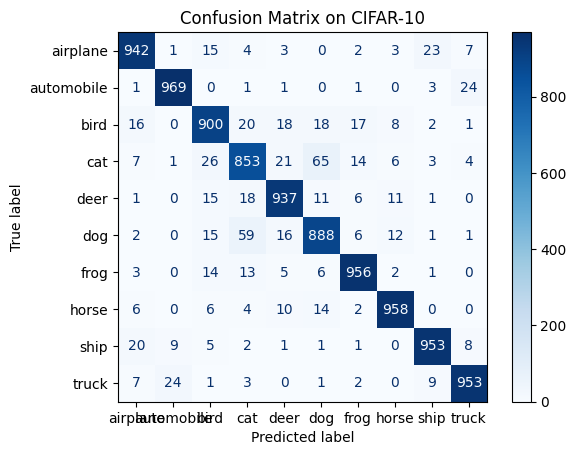

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import torch
import numpy as np

# Define class names for CIFAR-10
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

# Lists to hold predictions and labels
all_preds = []
all_labels = []

# Set model to evaluation mode
net.eval()
with torch.no_grad():
    for batch in test_dataloader:
        images = batch["img"].to(device)  # Assuming images are in "img" key
        labels = batch["label"].to(device)  # Assuming labels are in "label" key

        # Forward pass
        outputs = net(images)
        preds = torch.argmax(outputs, dim=1)

        # Append predictions and labels
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(torch.argmax(labels, dim=1).cpu().numpy())  # Convert one-hot to class indices

# Check lengths
assert len(all_preds) == len(all_labels), "Prediction and label lengths do not match"

# Generate confusion matrix
cm = confusion_matrix(all_labels, all_preds)

# Display confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap='Blues')
plt.title("Confusion Matrix on CIFAR-10")
plt.show()


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(all_labels, all_preds, target_names=class_names))

              precision    recall  f1-score   support

    airplane       0.94      0.94      0.94      1000
  automobile       0.97      0.97      0.97      1000
        bird       0.90      0.90      0.90      1000
         cat       0.87      0.85      0.86      1000
        deer       0.93      0.94      0.93      1000
         dog       0.88      0.89      0.89      1000
        frog       0.95      0.96      0.95      1000
       horse       0.96      0.96      0.96      1000
        ship       0.96      0.95      0.95      1000
       truck       0.95      0.95      0.95      1000

    accuracy                           0.93     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.93      0.93      0.93     10000



In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.preprocessing import label_binarize
all_test_probs = []

# Set model to evaluation mode
net.eval()
with torch.no_grad():
    for batch in test_dataloader:
        images = batch["img"].to(device)
        labels = batch["label"].to(device)

        # Forward pass
        outputs = net(images)

        # Store softmax outputs for ROC AUC calculation
        all_test_probs.extend(torch.nn.functional.softmax(outputs, dim=1).cpu().numpy())

# One-hot encode the labels
all_labels_onehot = label_binarize(all_labels, classes=list(range(10)))

# Assuming `all_test_probs` is the softmax output from your model
auc_score = roc_auc_score(all_labels_onehot, all_test_probs, average='macro')
print("Macro-average AUC:", auc_score)


/usr/local/lib/python3.11/dist-packages/torch/nn/functional.py:1538: UserWarning: dropout2d: Received a 2-D input to dropout2d, which is deprecated and will result in an error in a future release. To retain the behavior and silence this warning, please use dropout instead. Note that dropout2d exists to provide channel-wise dropout on inputs with 2 spatial dimensions, a channel dimension, and an optional batch dimension (i.e. 3D or 4D inputs).
  warnings.warn(warn_msg)


Macro-average AUC: 0.9969049555555556


In [ ]:
import numpy as np

per_class_correct = np.zeros(10)
per_class_total = np.zeros(10)

for i in range(len(all_labels)):
    label = all_labels[i]
    pred = all_preds[i]
    if label == pred:
        per_class_correct[label] += 1
    per_class_total[label] += 1

per_class_accuracy = 100 * per_class_correct / per_class_total

for idx, acc in enumerate(per_class_accuracy):
    print(f"Class {class_names[idx]} Accuracy: {acc:.2f}%")

Class airplane Accuracy: 94.20%
Class automobile Accuracy: 96.90%
Class bird Accuracy: 90.00%
Class cat Accuracy: 85.30%
Class deer Accuracy: 93.70%
Class dog Accuracy: 88.80%
Class frog Accuracy: 95.60%
Class horse Accuracy: 95.80%
Class ship Accuracy: 95.30%
Class truck Accuracy: 95.30%


In [ ]:
!pip install pillow

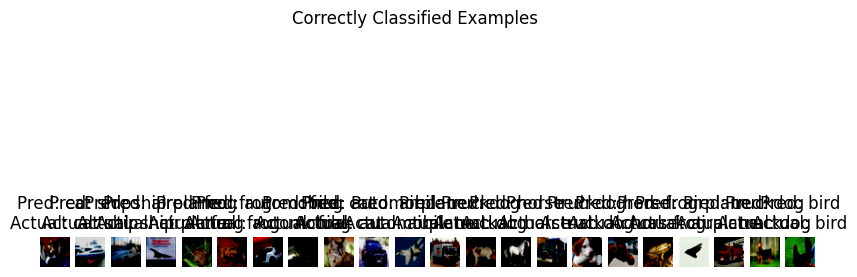

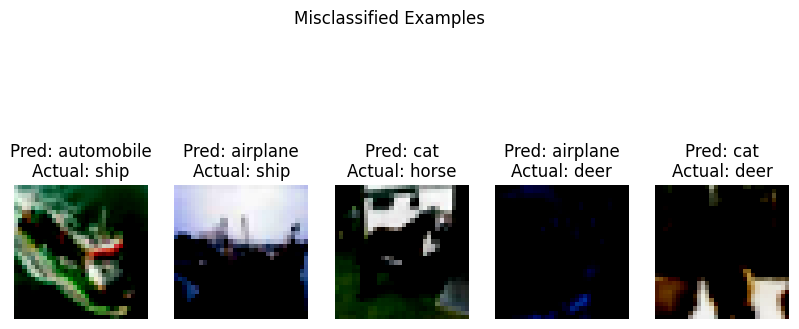

In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Load the CIFAR-10 dataset with transformation to tensor
transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=False)

# Initialize the model
num_classes = 10
net = AdvancedCNN(num_classes)

# Load the state dictionary
net.load_state_dict(torch.load('best.pt', map_location=torch.device('cuda' if torch.cuda.is_available() else 'cpu')))

# Set the model to evaluation mode
net.eval()

# Function to get class names
def get_class_names():
    return ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

# Function to display images
def display_images(images, labels, predicted_labels, title):
    plt.figure(figsize=(10, 5))
    for i in range(len(images)):
        plt.subplot(1, len(images), i+1)
        plt.imshow(np.transpose(images[i].numpy(), (1, 2, 0)))
        plt.title(f"Pred: {get_class_names()[predicted_labels[i]]}\nActual: {get_class_names()[labels[i]]}")
        plt.axis('off')
    plt.suptitle(title)
    plt.show()

# Main loop to find correctly and misclassified examples
correctly_classified = []
misclassified = []

with torch.no_grad():
    for images, labels in testloader:
        outputs = net(images)
        _, predicted = torch.max(outputs, 1)

        for i in range(len(labels)):
            if predicted[i] == labels[i]:
                correctly_classified.append((images[i], labels[i], predicted[i]))
            else:
                misclassified.append((images[i], labels[i], predicted[i]))

            if len(correctly_classified) >= 5 and len(misclassified) >= 5:
                break
        if len(correctly_classified) >= 5 and len(misclassified) >= 5:
            break

# Display correctly classified examples
correct_images = [x[0] for x in correctly_classified]
correct_labels = [x[1] for x in correctly_classified]
correct_predicted = [x[2] for x in correctly_classified]
display_images(correct_images, correct_labels, correct_predicted, "Correctly Classified Examples")

# Display misclassified examples
mis_images = [x[0] for x in misclassified]
mis_labels = [x[1] for x in misclassified]
mis_predicted = [x[2] for x in misclassified]
display_images(mis_images, mis_labels, mis_predicted, "Misclassified Examples")
